# Kidney Disease Classification from CT Scans

**Goal:** look at a kidney CT slice and decide which of four classes it belongs to: **Normal, Cyst, Stone or Tumor**.

**Approach:** transfer learning. Instead of training a network from scratch (which needs far more than ~12k images), we start from **EfficientNet-B0**, a network already trained on ImageNet, and adapt it to kidney CT images.

**Pipeline**

1. Setup (imports, config, reproducibility)
2. Load the data and remove duplicates
3. Stratified train / validation / test split
4. Preprocessing and augmentation
5. Datasets and data loaders
6. Model, loss function and class weights
7. Training: stage 1 (new head only), stage 2 (fine-tune the top of the backbone)
8. Evaluation on the test set
9. Grad-CAM explainability
10. Save the model for the FastAPI app

**Before you run:** download the Kaggle *CT Kidney Dataset (Normal, Cyst, Tumor and Stone)* and place it in `data/` with one sub-folder per class (`data/Cyst`, `data/Normal`, `data/Stone`, `data/Tumor`).

> Educational project only. Not a medical device.

## 1. Setup

We import the libraries, then keep every tunable value in one config cell so experiments are easy to change and repeat.

In [2]:
import hashlib
import os
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

In [3]:
SEED = 42
DATA_DIR = Path("data")
IMG_SIZE = 224
BATCH_SIZE = 32          # drop to 16 if the GPU runs out of memory
STAGE1_EPOCHS = 5
STAGE2_EPOCHS = 15
PATIENCE = 4             # early-stopping patience (epochs without improvement)

**Reproducibility and device.** Neural-network training is random (weight initialisation, shuffling, augmentation). Fixing the seeds makes runs repeatable enough to compare. Training on a GPU is dramatically faster than on a CPU, so we pick CUDA when it is available.

In [4]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Path("assets").mkdir(exist_ok=True)
Path("model").mkdir(exist_ok=True)
print("device:", device)

device: cuda


## 2. Load the data and remove duplicates

The folder name is the label, so the class list comes straight from `data/`.

**Why remove duplicates?** If the same image appears twice and one copy lands in the training set while the other lands in the test set, the model is being tested on something it has already seen. That is **data leakage** and it inflates the score. Here we hash every file with MD5 and keep only the first copy of each.

**Limitation:** MD5 only catches byte-identical files. This dataset has no patient IDs, so neighbouring slices from the same patient can still end up in different splits. Keep that in mind when reading the results.

In [5]:
classes = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
print(classes)

['Cyst', 'Normal', 'Stone', 'Tumor']


In [6]:
files, labels, seen = [], [], set()

for idx, cls in enumerate(classes):
    for f in sorted((DATA_DIR / cls).glob("*")):
        if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        digest = hashlib.md5(f.read_bytes()).hexdigest()
        if digest in seen:
            continue
        seen.add(digest)
        files.append(f)
        labels.append(idx)

Check how many images each class has. The classes are not equally sized, which matters later (class weights).

In [7]:
print({classes[i]: n for i, n in sorted(Counter(labels).items())})

{'Cyst': 3284, 'Normal': 5002, 'Stone': 1360, 'Tumor': 2283}


## 3. Train / validation / test split

Each subset has a different job:

| Subset | Used for | Share |
|---|---|---|
| **Train** | Learning the weights | 70% |
| **Validation** | Choosing the best epoch, early stopping | 15% |
| **Test** | One final, unbiased score | 15% |

The split is **stratified**, meaning every subset keeps the same class proportions as the full dataset, so the rare classes are not accidentally missing from the test set. We split twice: first 70 / 30, then the 30% is halved into validation and test. The test set is not touched until the evaluation section.

In [8]:
tr_f, tmp_f, tr_y, tmp_y = train_test_split(
    files, labels, test_size=0.30, stratify=labels, random_state=SEED)

In [9]:
va_f, te_f, va_y, te_y = train_test_split(
    tmp_f, tmp_y, test_size=0.50, stratify=tmp_y, random_state=SEED)

print("train:", len(tr_f), "| val:", len(va_f), "| test:", len(te_f))

train: 8350 | val: 1789 | test: 1790


## 4. Preprocessing and augmentation

**Resize to 224 x 224.** The standard input size for EfficientNet-B0.

**Normalise with the ImageNet mean and standard deviation.** The backbone was pretrained on ImageNet images normalised this way, so our images must look statistically similar to what it expects.

**Augmentation (training images only).** Each epoch the model sees slightly different versions of the same images (flipped, rotated, brighter or darker). This acts like extra data and reduces overfitting. Validation and test images are only resized and normalised so that scores are stable and comparable.

In [10]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])

In [11]:
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    norm,
])

## 5. Dataset and DataLoader

A PyTorch `Dataset` knows how to return one `(image tensor, label)` pair. Images are read from disk only when requested, so the whole dataset never has to fit in memory. The `DataLoader` then groups samples into batches, shuffles the training data every epoch, and can load images in parallel worker processes.

CT slices are grayscale, so we convert them to 3-channel RGB because the pretrained network expects 3 channels.

In [12]:
class CTData(Dataset):
    def __init__(self, files, labels, tf):
        self.files, self.labels, self.tf = files, labels, tf

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert("RGB")
        return self.tf(img), self.labels[i]

In [13]:
workers = 0 if os.name == "nt" else 4   # worker processes are unreliable in Jupyter on Windows


def make_loader(files, labels, tf, shuffle=False):
    return DataLoader(CTData(files, labels, tf), BATCH_SIZE, shuffle=shuffle,
                      num_workers=workers, pin_memory=device.type == "cuda")

In [14]:
train_dl = make_loader(tr_f, tr_y, train_tf, shuffle=True)
val_dl = make_loader(va_f, va_y, eval_tf)
test_dl = make_loader(te_f, te_y, eval_tf)

## 6. Model, loss and class weights

### Transfer learning
A CNN learns features in layers. **Early layers** detect edges and textures, **middle layers** detect shapes and patterns, and **the final layers** are specific to the original task (ImageNet's 1000 classes). Edges and textures are useful for CT images too, so we keep the pretrained backbone and replace only the last layer with a new 4-class layer.

**EfficientNet-B0** is a small, efficient network (about 5M parameters), which suits a modest GPU and an easy deployment.

In [15]:
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))
model = model.to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\LENOV/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100.0%


### Loss function and class weights
**Cross-entropy** loss measures how far the predicted probabilities are from the true label: it is small when the model is confident and right, and large when it is confident and wrong.

Because the classes are imbalanced, a model could score well just by favouring the biggest class. **Class weights** (`total / (n_classes x class_count)`) make each mistake on a rare class cost more, so all four classes matter.

In [16]:
counts = np.bincount(tr_y)
class_weights = torch.tensor(len(tr_y) / (len(classes) * counts), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print(dict(zip(classes, class_weights.cpu().numpy().round(2))))

{'Cyst': np.float32(0.91), 'Normal': np.float32(0.6), 'Stone': np.float32(2.19), 'Tumor': np.float32(1.31)}


## 7. Training machinery

One training step on a batch of images:

1. **Forward pass:** the model outputs a score for each of the 4 classes.
2. **Loss:** compare the scores with the true labels.
3. **Backward pass (backpropagation):** compute how much each trainable weight contributed to the loss.
4. **Optimiser step:** nudge each weight slightly to reduce the loss. We use **AdamW**, an adaptive optimiser with weight decay (a penalty that keeps weights small and reduces overfitting).

One full pass over the training set is an **epoch**. After each epoch we run a **validation pass** with no weight updates to see how the model does on unseen images.

**Mixed precision (AMP):** on a CUDA GPU, most calculations run in 16-bit floats, which uses less memory and is faster. The `GradScaler` rescales the loss so very small gradients do not vanish in 16-bit.

In [17]:
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
history = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}

`run_epoch` does one pass over a loader. If an optimiser is given it trains, otherwise it only evaluates. It returns the average loss and the **macro-F1** score (explained in the evaluation section).

In [18]:
def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, preds, truth = 0.0, [], []

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device.type, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)

            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total += loss.item() * len(y)
            preds += out.argmax(1).tolist()
            truth += y.tolist()

    return total / len(truth), f1_score(truth, preds, average="macro")

`fit` repeats `run_epoch` and adds two safeguards:

- **Checkpointing:** whenever validation macro-F1 improves, the weights are saved to `best.pt`.
- **Early stopping:** if validation macro-F1 has not improved for `PATIENCE` epochs, training stops, because the model has probably started to overfit.

At the end the best checkpoint is loaded back, not the last one.

In [19]:
def fit(optimizer, epochs, best=-1.0):
    wait = 0
    for ep in range(1, epochs + 1):
        train_loss, train_f1 = run_epoch(train_dl, optimizer)
        val_loss, val_f1 = run_epoch(val_dl)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_f1"].append(train_f1)
        history["val_f1"].append(val_f1)
        print(f"epoch {ep:2d} | train loss {train_loss:.3f} f1 {train_f1:.3f} "
              f"| val loss {val_loss:.3f} f1 {val_f1:.3f}")

        if val_f1 > best:
            best, wait = val_f1, 0
            torch.save(model.state_dict(), "best.pt")
        else:
            wait += 1
            if wait >= PATIENCE:
                print("early stopping")
                break

    model.load_state_dict(torch.load("best.pt", map_location=device))
    return best

## 8. Stage 1: train the new head only

The new classification layer starts with random weights, so at first it makes large, noisy errors. If the whole network were trainable, those errors would flow back and damage the good pretrained features.

So first we **freeze the backbone** (`requires_grad = False`) and train only the new head, using a relatively high learning rate (`1e-3`). This teaches the head to read the backbone's existing features.

In [20]:
for p in model.features.parameters():
    p.requires_grad = False

opt = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

In [21]:
best = fit(opt, STAGE1_EPOCHS)

epoch  1 | train loss 0.825 f1 0.665 | val loss 0.541 f1 0.798
epoch  2 | train loss 0.587 f1 0.759 | val loss 0.452 f1 0.822
epoch  3 | train loss 0.506 f1 0.793 | val loss 0.386 f1 0.852
epoch  4 | train loss 0.485 f1 0.799 | val loss 0.341 f1 0.855
epoch  5 | train loss 0.464 f1 0.810 | val loss 0.341 f1 0.862


## 9. Stage 2: fine-tune the top of the backbone

Now that the head is sensible, we **unfreeze the last blocks of the backbone** (the last two MBConv stages and the final 1x1 convolution) so their features can shift from "general objects" to "kidney CT patterns".

We use **discriminative learning rates**: a very small rate (`1e-5`) for the pretrained blocks and a larger one (`1e-4`) for the head. Large updates to pretrained layers would erase what they already know (*catastrophic forgetting*).

Early layers stay frozen because their edge and texture detectors are already general enough.

In [22]:
for p in model.features[-3:].parameters():
    p.requires_grad = True

opt = torch.optim.AdamW([
    {"params": model.features[-3:].parameters(), "lr": 1e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4},
], weight_decay=1e-4)

In [24]:
best = fit(opt, STAGE2_EPOCHS, best)
print("best validation macro-F1:", round(best, 3))

epoch  1 | train loss 0.334 f1 0.864 | val loss 0.172 f1 0.940
epoch  2 | train loss 0.290 f1 0.877 | val loss 0.127 f1 0.966
epoch  3 | train loss 0.234 f1 0.907 | val loss 0.097 f1 0.973
epoch  4 | train loss 0.204 f1 0.919 | val loss 0.079 f1 0.974
epoch  5 | train loss 0.173 f1 0.934 | val loss 0.073 f1 0.974
epoch  6 | train loss 0.162 f1 0.935 | val loss 0.046 f1 0.984
epoch  7 | train loss 0.136 f1 0.950 | val loss 0.043 f1 0.986
epoch  8 | train loss 0.118 f1 0.954 | val loss 0.033 f1 0.991
epoch  9 | train loss 0.114 f1 0.957 | val loss 0.036 f1 0.989
epoch 10 | train loss 0.099 f1 0.960 | val loss 0.027 f1 0.992
epoch 11 | train loss 0.098 f1 0.962 | val loss 0.020 f1 0.994
epoch 12 | train loss 0.089 f1 0.966 | val loss 0.017 f1 0.995
epoch 13 | train loss 0.077 f1 0.971 | val loss 0.012 f1 0.997
epoch 14 | train loss 0.077 f1 0.969 | val loss 0.012 f1 0.996
epoch 15 | train loss 0.069 f1 0.975 | val loss 0.009 f1 0.999
best validation macro-F1: 0.999


### Reading the learning curves

- Train and validation loss both falling: the model is learning.
- Train loss falling while validation loss rises: **overfitting** (memorising the training images).
- Both staying high: **underfitting** (needs more capacity, a higher learning rate or more epochs).

The curves cover both stages one after the other, so a jump where stage 2 begins is normal.

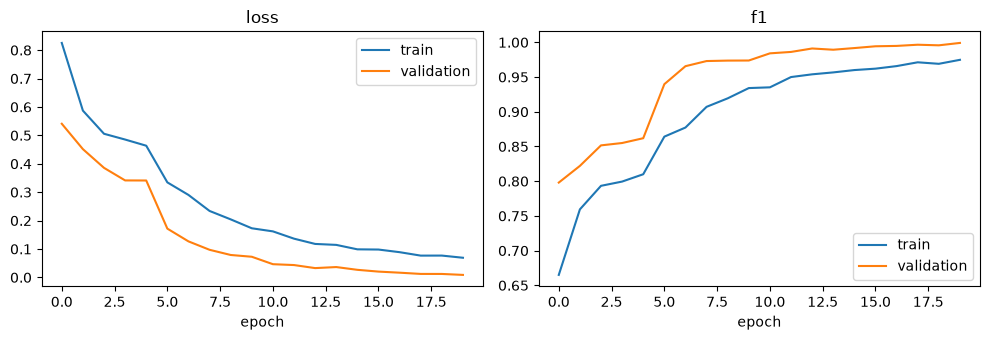

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, ["loss", "f1"]):
    ax.plot(history[f"train_{name}"], label="train")
    ax.plot(history[f"val_{name}"], label="validation")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.legend()

plt.tight_layout()
plt.savefig("assets/training_curves.png", dpi=150)
plt.show()

## 10. Evaluation on the test set

This is the first and only time the model sees the test set, so the numbers are an honest estimate of performance on new images.

### Metrics used

| Metric | Question it answers |
|---|---|
| **Accuracy** | What fraction of all images were classified correctly? Can look good even if a rare class is handled badly. |
| **Precision** (per class) | Of the images the model called "Tumor", how many really were tumors? Low precision means false alarms. |
| **Recall** (per class) | Of all real tumors, how many did the model find? Low recall means missed cases. |
| **F1-score** (per class) | The balance of precision and recall in one number. |
| **Macro-F1** | The plain average of the four F1 scores. Every class counts equally, so it is not inflated by the biggest class. This is the headline metric. |
| **Confusion matrix** | A grid of true class vs. predicted class that shows exactly which classes get confused. |

In a medical setting **recall matters most**: missing a tumor is worse than a false alarm. That is why we look at per-class numbers and not just accuracy.

In [26]:
model.eval()
preds, truth = [], []

with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()

In [27]:
print(classification_report(truth, preds, target_names=classes, digits=3))
print("macro-F1:", round(f1_score(truth, preds, average="macro"), 3))

              precision    recall  f1-score   support

        Cyst      1.000     0.988     0.994       493
      Normal      0.999     1.000     0.999       751
       Stone      0.971     1.000     0.986       204
       Tumor      1.000     0.997     0.999       342

    accuracy                          0.996      1790
   macro avg      0.993     0.996     0.994      1790
weighted avg      0.996     0.996     0.996      1790

macro-F1: 0.994


The confusion matrix: rows are the true class, columns are the predicted class. A perfect model has numbers only on the diagonal.

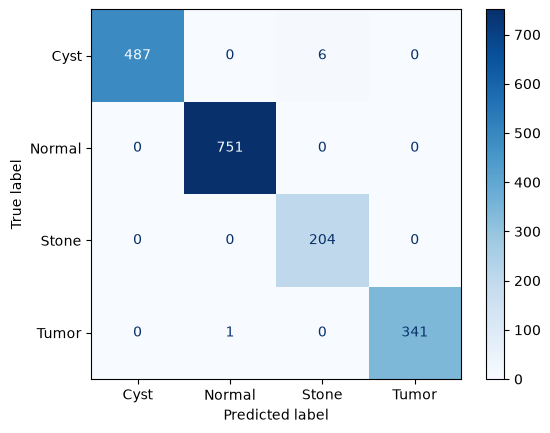

In [28]:
ConfusionMatrixDisplay(confusion_matrix(truth, preds), display_labels=classes).plot(cmap="Blues")
plt.savefig("assets/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Grad-CAM: where is the model looking?

A high score alone does not show that the model learned the right thing. **Grad-CAM** (Selvaraju et al., 2017) produces a heatmap of the image regions that pushed the model towards its prediction:

1. Take the feature maps from the last convolutional layer.
2. Compute the gradient of the predicted class score with respect to those maps.
3. Average each channel's gradient to get one importance weight per channel.
4. Take the weighted sum of the maps and keep only positive values (ReLU).
5. Resize the result to the image size and overlay it (red = most influential).

Treat it as a sanity check, not proof. If the heat sits on the kidney, that is reassuring. If it sits on the table or the image border, the model may be using shortcuts.

In [29]:
def gradcam(x):
    feats = model.features(x[None].to(device))
    feats.retain_grad()
    out = model.classifier(torch.flatten(model.avgpool(feats), 1))

    model.zero_grad()
    out[0, out.argmax(1).item()].backward()

    weights = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * feats).sum(1))[0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

Pick four correct and up to four wrong predictions from the test set, so we can compare what the model looks at in each case.

In [30]:
right = [i for i, (p, t) in enumerate(zip(preds, truth)) if p == t]
wrong = [i for i, (p, t) in enumerate(zip(preds, truth)) if p != t]

rng = random.Random(SEED)
picks = rng.sample(right, 4) + rng.sample(wrong, min(4, len(wrong)))

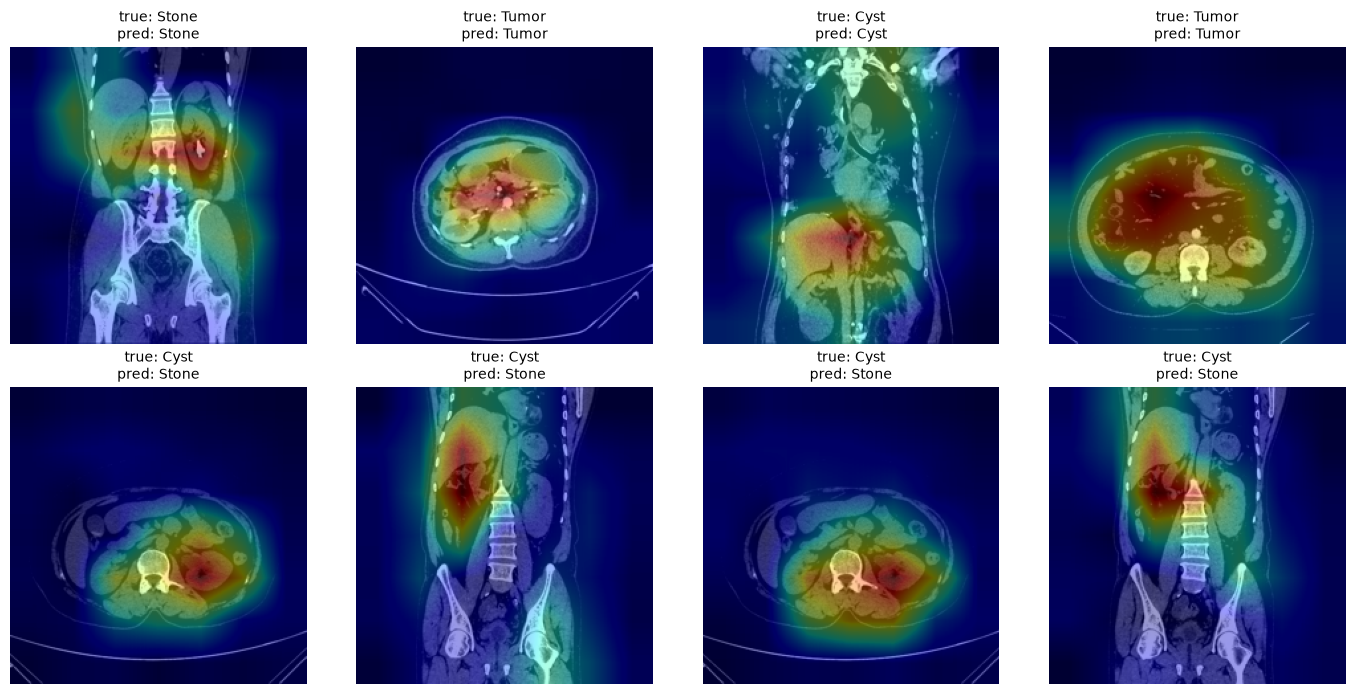

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis("off")

for ax, i in zip(axes.flat, picks):
    cam = gradcam(test_dl.dataset[i][0])
    cam = Image.fromarray((cam * 255).astype("uint8")).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

    ax.imshow(Image.open(te_f[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    ax.imshow(np.array(cam) / 255, cmap="jet", alpha=0.4)
    ax.set_title(f"true: {classes[truth[i]]}\npred: {classes[preds[i]]}", fontsize=10)

plt.tight_layout()
plt.savefig("assets/gradcam_examples.png", dpi=150)
plt.show()

## 12. Save the model

We save the weights together with the class names, so the FastAPI app can rebuild the same network and map output numbers back to labels. This file is what `app.py` loads.

In [32]:
torch.save({"state_dict": model.state_dict(), "classes": classes}, "model/model.pt")

## Limitations

- No patient IDs are available, so slices from the same patient may appear in more than one split. The scores may therefore be optimistic for truly new patients.
- Trained on one public dataset. Scans from other scanners or hospitals are untested.
- It classifies single 2D slices and does not use 3D context.
- Not clinically validated. Educational use only.